# Lab 01 · A/B 테스트를 시뮬레이션으로 이해하기

**이 실습이 다루는 자료** ([필독 목록](../READING_LIST.md) · [실습 가이드](../PRACTICE.md))

| 절 | 직접 확인할 것 | 관련 자료 |
|---|---|---|
| 1 | 실험 한 번을 분석하는 법: 차이, 신뢰구간, p-value | Kohavi et al. (2009) *Controlled experiments on the web* |
| 2 | 실험 전에 정하는 것: 표본 크기와 검정력 | 같은 논문, *Trustworthy Online Controlled Experiments* |
| 3 | 중간에 들여다보고 멈추면 생기는 일 (peeking) | Evan Miller *How Not To Run an A/B Test*, Johari et al. (2017) |
| 4 | 언제 봐도 유효한 p-value (mSPRT) | Johari et al. (2015) *Always Valid Inference* |
| 5 | 실험 전 데이터로 분산 줄이기 | Deng et al. (2013) *CUPED* |
| 6 | 실험이 고장났다는 신호: SRM | Fabijan et al. (2019) *Diagnosing Sample Ratio Mismatch* |

**소요 시간**: 90분 · **패키지**: numpy, pandas, scipy, matplotlib  
선수 지식: [인과·실험 기초](../../00_Foundations/07_causal-experiment-basics.md), [통계 Lab 01](../../01_Statistics_Math/labs/lab01_sampling_bootstrap_pvalues.ipynb)

시뮬레이션의 장점은 **정답(참 효과)을 알고 있다**는 것입니다. 그래서 "이 분석 절차가 얼마나 자주 틀리는가"를 직접 셀 수 있습니다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
rng = np.random.default_rng(1)
plt.rcParams.update({"figure.figsize": (7, 3.3), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

## 1. 실험 한 번 분석하기

구매 전환율이 대조군(A) 10.0%, 실험군(B) 10.5%인 세계를 만듭니다. 참 효과는 +0.5%p(상대적으로 +5%)입니다. 그룹당 2만 명으로 실험합니다.

In [2]:
def analyze(conv_a, n_a, conv_b, n_b):
    pa, pb = conv_a / n_a, conv_b / n_b
    se = np.sqrt(pa * (1 - pa) / n_a + pb * (1 - pb) / n_b)
    z = (pb - pa) / se
    return dict(lift=pb - pa, ci_low=pb - pa - 1.96 * se, ci_high=pb - pa + 1.96 * se, p_value=2 * (1 - stats.norm.cdf(abs(z))))

n = 20_000
one = analyze(rng.binomial(n, 0.100), n, rng.binomial(n, 0.105), n)
print({k: round(float(v), 4) for k, v in one.items()})

{'lift': 0.0027, 'ci_low': -0.0032, 'ci_high': 0.0086, 'p_value': 0.3685}


이 한 번의 결과가 유의하게 나왔든 아니든, 그것은 **운**입니다. 같은 실험을 여러 번 반복하면 얼마나 자주 유의하게 나올까요? 그 비율이 **검정력**입니다.

## 2. 표본 크기와 검정력

그룹당 필요한 표본 수(유의수준 5%, 검정력 80%): $\;n=\dfrac{2\,(z_{0.975}+z_{0.80})^2\,\sigma^2}{\delta^2}$, 전환율 지표에서는 $\sigma^2=p(1-p)$.

✍️ **예측**: 기준 전환율 10%에서 +0.5%p를 검출하려면 그룹당 몇 명이 필요할까요? 효과가 절반(+0.25%p)이면 몇 배가 필요할까요?

In [3]:
def required_n(p, delta, power=0.8, alpha=0.05):
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    return int(np.ceil(2 * z**2 * p * (1 - p) / delta**2))

def simulated_power(n, p_a, p_b, reps=20000):
    a, b = rng.binomial(n, p_a, reps), rng.binomial(n, p_b, reps)
    res = analyze(a, n, b, n)
    return np.mean(res["p_value"] < 0.05)

print("필요 표본 수(그룹당):  +0.5%p →", f"{required_n(0.10, 0.005):,}", "  |  +0.25%p →", f"{required_n(0.10, 0.0025):,}")
ns = [5_000, 20_000, 56_600, 100_000]
print(pd.DataFrame({"n_per_group": ns, "power(참 효과 +0.5%p)": [simulated_power(k, 0.100, 0.105) for k in ns],
                    "false_positive_rate(효과 없음)": [simulated_power(k, 0.100, 0.100) for k in ns]}).round(3).to_string(index=False))

필요 표본 수(그룹당):  +0.5%p → 56,512   |  +0.25%p → 226,048
 n_per_group  power(참 효과 +0.5%p)  false_positive_rate(효과 없음)
        5000               0.131                       0.050
       20000               0.383                       0.050
       56600               0.790                       0.047
      100000               0.959                       0.049


- 공식이 준 약 5만 6천 명에서 검정력이 약 80%입니다. 1절의 2만 명 실험은 검정력이 40%도 안 됩니다. **유의하지 않게 나와도 "효과가 없다"는 뜻이 아닙니다.**
- 효과가 절반이면 표본은 **4배** 필요합니다($\delta^2$ 에 반비례). 작은 개선을 측정하는 것이 어려운 이유입니다.
- 효과가 없을 때 유의하게 나오는 비율(1종 오류)은 표본 크기와 무관하게 약 5%입니다.

## 3. Peeking: 매일 들여다보고 유의하면 멈추기

효과가 **전혀 없는** A/A 실험을 20일간 진행합니다(매일 그룹당 1,000명). 매일 p-value를 확인해서 0.05 아래로 내려가는 순간 "성공!"이라며 멈춘다고 합시다.

✍️ **예측**: 20일 중 한 번이라도 p<0.05가 나오는 실험은 전체의 몇 %일까요? (하루만 보면 5%)

마지막 날 한 번만 볼 때의 오탐률       = 0.048
매일 보고 유의하면 멈출 때의 오탐률    = 0.234


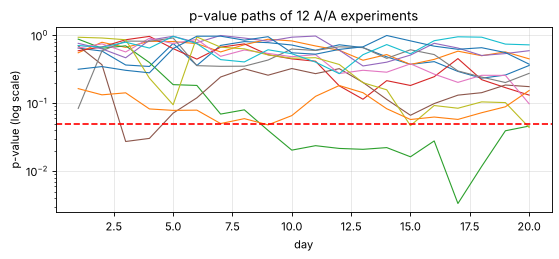

In [4]:
def daily_p_values(p_a, p_b, days=20, per_day=1000, reps=4000):
    a = rng.binomial(per_day, p_a, (reps, days)).cumsum(axis=1); b = rng.binomial(per_day, p_b, (reps, days)).cumsum(axis=1)
    n_cum = per_day * np.arange(1, days + 1)[None, :]
    pa, pb = a / n_cum, b / n_cum
    se = np.sqrt(pa * (1 - pa) / n_cum + pb * (1 - pb) / n_cum)
    return 2 * (1 - stats.norm.cdf(np.abs(pb - pa) / se)), (pb - pa), n_cum

p_aa, _, _ = daily_p_values(0.10, 0.10)
print(f"마지막 날 한 번만 볼 때의 오탐률       = {np.mean(p_aa[:, -1] < 0.05):.3f}")
print(f"매일 보고 유의하면 멈출 때의 오탐률    = {np.mean((p_aa < 0.05).any(axis=1)):.3f}")
plt.figure(figsize=(8, 3))
for path in p_aa[:12]: plt.plot(range(1, 21), path, lw=1)
plt.axhline(0.05, color="r", ls="--"); plt.yscale("log"); plt.xlabel("day"); plt.ylabel("p-value (log scale)"); plt.title("p-value paths of 12 A/A experiments"); plt.show()

효과가 없는데도 4번에 1번꼴로 "유의한 결과"를 얻습니다. p-value는 계속 출렁이기 때문에, 기회를 여러 번 주면 언젠가 0.05 아래를 지나갑니다. **고정 표본 검정은 "한 번만 본다"는 약속 아래에서만 5%를 보장합니다.**

## 4. 언제 봐도 유효한 p-value (Johari et al.)

해결책 하나는 순차 검정입니다. mSPRT는 "효과가 0"이라는 가설과 "효과가 0 근처 어딘가($\mathcal N(0,\tau^2)$)"라는 가설의 **가능도비** $\Lambda_n$ 를 계속 추적합니다. 차이의 추정치를 $\bar d_n$, 그 분산을 $V_n$ 이라 하면

$$\Lambda_n=\sqrt{\frac{V_n}{V_n+\tau^2}}\;\exp\!\left(\frac{\tau^2\,\bar d_n^{\,2}}{2V_n(V_n+\tau^2)}\right),\qquad p_n^{\text{always}}=\min\Big(1,\ \frac{1}{\max_{k\le n}\Lambda_k}\Big)$$

이 p-value는 한 번 내려가면 다시 올라가지 않고, **몇 번을 들여다보든** 오탐률이 α 이하로 보장됩니다.

✍️ **예측**: 공짜일까요? 같은 20일 실험에서 검정력은 고정 표본 검정과 비교해 어떨까요?

In [5]:
def always_valid_p(diff, n_cum, p_pooled=0.10, tau=0.01):
    V = 2 * p_pooled * (1 - p_pooled) / n_cum
    lam = np.sqrt(V / (V + tau**2)) * np.exp(tau**2 * diff**2 / (2 * V * (V + tau**2)))
    return np.minimum(1, 1 / np.maximum.accumulate(lam, axis=1))

rows = []
for label, p_b in [("효과 없음 (A/A)", 0.100), ("참 효과 +1%p", 0.110)]:
    p_fixed, diff, n_cum = daily_p_values(0.10, p_b)
    p_seq = always_valid_p(diff, n_cum)
    stopped = (p_seq < 0.05)
    rows.append({"상황": label, "고정 표본(마지막 날 1회)": np.mean(p_fixed[:, -1] < 0.05), "매일 보고 멈춤(잘못된 방법)": np.mean((p_fixed < 0.05).any(axis=1)),
                 "always-valid p (매일 봐도 됨)": np.mean(stopped.any(axis=1)),
                 "always-valid 평균 종료일": np.where(stopped.any(axis=1), stopped.argmax(axis=1) + 1, 20).mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

         상황  고정 표본(마지막 날 1회)  매일 보고 멈춤(잘못된 방법)  always-valid p (매일 봐도 됨)  always-valid 평균 종료일
효과 없음 (A/A)            0.050             0.249                     0.013               19.891
  참 효과 +1%p            0.915             0.954                     0.702               13.956


표 읽기 (각 칸은 "유의하다고 판정한 비율")
- **효과 없음** 행: 고정 표본은 약 5%, 매일 보고 멈추면 20%대, always-valid는 **5% 이하**로 유지됩니다.
- **참 효과 +1%p** 행: always-valid의 검정력은 고정 표본보다 낮습니다. 대신 효과가 클 때 **일찍 끝낼 수 있습니다**(평균 종료일). 언제든 볼 수 있는 자유의 대가가 검정력입니다.
- 실무에서는 (a) 기간을 미리 정하고 지키거나, (b) 순차 검정(mSPRT, group sequential 등)을 쓰거나 둘 중 하나를 택합니다. Spotify 글이 여러 순차 방법의 장단점을 비교합니다.

## 5. CUPED: 실험 전 데이터로 분산 줄이기 (Deng et al., 2013)

사용자의 **실험 전** 구매액 $X$ 는 실험 중 구매액 $Y$ 와 상관이 높습니다. 그리고 무작위 배정 덕분에 $X$ 는 처치와 무관합니다. 그래서 $Y$ 에서 "$X$ 로 설명되는 부분"을 빼도 효과 추정은 그대로이고 잡음만 줄어듭니다.

$$Y^{cuped}=Y-\theta\,(X-\bar X),\qquad \theta=\frac{\text{Cov}(X,Y)}{\text{Var}(X)},\qquad \text{Var}(Y^{cuped})=(1-\rho^2)\,\text{Var}(Y)$$

✍️ **예측**: $X$ 와 $Y$ 의 상관이 0.7이면 분산은 몇 % 줄어들까요? 같은 검정력을 얻는 데 필요한 표본은?

In [6]:
def simulate_revenue(n, effect, rho=0.7):
    x = rng.gamma(2.0, 10.0, 2 * n)                                    # 실험 전 구매액
    noise_sd = x.std() * np.sqrt(1 / rho**2 - 1)                       # corr(x, y) = rho 가 되도록
    y = x + rng.normal(0, noise_sd, 2 * n)
    t = np.repeat([0, 1], n); rng.shuffle(t)                           # 무작위 배정
    return x, y + effect * t, t

def diff_and_se(v, t):
    a, b = v[t == 0], v[t == 1]
    return b.mean() - a.mean(), np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))

def cuped(x, y):
    theta = np.cov(x, y)[0, 1] / x.var(ddof=1)
    return y - theta * (x - x.mean())

x, y, t = simulate_revenue(5000, effect=0.6)
d_raw, se_raw = diff_and_se(y, t); d_cup, se_cup = diff_and_se(cuped(x, y), t)
print(f"상관계수 = {np.corrcoef(x, y)[0, 1]:.2f}  →  이론상 분산 감소 = {np.corrcoef(x, y)[0, 1]**2:.0%}")
print(f"보통 분석 : 차이 = {d_raw:.3f} ± {1.96 * se_raw:.3f}")
print(f"CUPED    : 차이 = {d_cup:.3f} ± {1.96 * se_cup:.3f}   (신뢰구간 폭이 {se_cup / se_raw:.2f}배)   참 효과 = 0.6")

상관계수 = 0.70  →  이론상 분산 감소 = 49%
보통 분석 : 차이 = 0.355 ± 0.797
CUPED    : 차이 = 0.446 ± 0.570   (신뢰구간 폭이 0.72배)   참 효과 = 0.6


In [7]:
# 반복 실험으로 확인: 편향은 없는가, 검정력은 얼마나 오르는가
est_raw, est_cup, sig_raw, sig_cup = [], [], [], []
for _ in range(1500):
    x, y, t = simulate_revenue(5000, effect=0.6)
    d1, s1 = diff_and_se(y, t); d2, s2 = diff_and_se(cuped(x, y), t)
    est_raw.append(d1); est_cup.append(d2); sig_raw.append(abs(d1 / s1) > 1.96); sig_cup.append(abs(d2 / s2) > 1.96)
print(f"추정치 평균  보통: {np.mean(est_raw):.3f}   CUPED: {np.mean(est_cup):.3f}   (참 효과 0.6 → 둘 다 편향 없음)")
print(f"검정력       보통: {np.mean(sig_raw):.2f}    CUPED: {np.mean(sig_cup):.2f}")

추정치 평균  보통: 0.604   CUPED: 0.596   (참 효과 0.6 → 둘 다 편향 없음)
검정력       보통: 0.32    CUPED: 0.54


- 같은 실험, 같은 사용자인데 분석만 바꿔 신뢰구간이 약 0.7배로 줄고 검정력이 크게 오릅니다. 분산이 절반이면 **필요한 표본(=실험 기간)도 절반**입니다.
- 추정치의 평균은 두 방법 모두 참 효과와 같습니다. $X$ 가 **실험 전에** 정해진 값이라 처치의 영향을 받지 않기 때문입니다. 실험 **중**에 측정된 변수를 넣으면 편향이 생길 수 있습니다.
- [LLM Lab 03](../../04_NLP_LLM/labs/lab03_llm_eval_error_bars.ipynb)의 "짝지은 차이"와 같은 발상입니다: 처치와 무관한 공통 변동을 빼기.

## 6. SRM: 표본 비율이 어긋나면 결과를 믿지 않는다 (Fabijan et al., 2019)

50:50으로 배정했는데 로그에 남은 사용자 수가 다르면, 어딘가에서 사용자가 **선택적으로** 빠지고 있다는 뜻입니다. 카이제곱 검정으로 확인합니다.

✍️ **예측**: 50,000명 대 49,300명. 이 정도 차이는 우연일까요?

In [8]:
def srm_p_value(n_a, n_b): return stats.chisquare([n_a, n_b]).pvalue
print(f"50,000 vs 49,300 → SRM p-value = {srm_p_value(50_000, 49_300):.4f}")
print(f"50,000 vs 49,800 → SRM p-value = {srm_p_value(50_000, 49_800):.4f}")

50,000 vs 49,300 → SRM p-value = 0.0263
50,000 vs 49,800 → SRM p-value = 0.5267


700명 차이는 우연으로 보기 어렵고(p≈0.03), 200명 차이는 흔히 나올 수 있는 수준입니다. SRM 검사는 모든 실험에 자동으로 걸어 두는 것이라, 실무에서는 0.05보다 훨씬 엄격한 기준(예: 0.001)을 쓰는 경우가 많습니다.

왜 중요한지 직접 만들어 봅니다. **참 효과는 0**입니다. 다만 실험군의 새 페이지가 느려서, 원래 활동이 적은 사용자의 일부가 로그가 기록되기 전에 이탈한다고 합시다.

In [9]:
n = 50_000
engagement = rng.gamma(2.0, 5.0, 2 * n)                                 # 사용자의 원래 활동 수준
t = np.repeat([0, 1], n)
y = engagement + rng.normal(0, 3, 2 * n)                                # 결과 지표. 처치 효과 없음
low = engagement < np.quantile(engagement, 0.15)
logged = ~((t == 1) & low & (rng.random(2 * n) < 0.35))                 # 실험군의 저활동 사용자 35%가 기록에서 빠진다
d, se = diff_and_se(y[logged], t[logged])
print(f"기록된 사용자 수  A = {np.sum(logged & (t == 0)):,}   B = {np.sum(logged & (t == 1)):,}   SRM p-value = {srm_p_value(np.sum(logged & (t == 0)), np.sum(logged & (t == 1))):.1e}")
print(f"측정된 효과 = {d:+.3f} ± {1.96 * se:.3f}   (참 효과 0인데 '유의한 개선'으로 보인다)")

기록된 사용자 수  A = 50,000   B = 47,395   SRM p-value = 7.0e-17
측정된 효과 = +0.379 ± 0.096   (참 효과 0인데 '유의한 개선'으로 보인다)


활동이 적은 사용자가 실험군에서만 빠졌으니 실험군의 평균이 올라갑니다. 지표만 보면 성공한 실험입니다. **SRM 검사는 결과를 보기 전에 가장 먼저 하는 건강 검진**이고, 실패하면 결과 해석을 멈추고 원인(로깅, 리다이렉트, 봇 필터 등)을 찾습니다.

---
## 직접 해보기

1. **(실험 기간)** 하루 방문자가 그룹당 8,000명, 기준 전환율 4%일 때 상대 5% 개선(+0.2%p)을 검정력 80%로 검출하려면 며칠이 필요한가요? 요일 효과를 고려하면 며칠로 잡아야 할까요?
2. **(약한 공변량)** 5절에서 상관을 0.3으로 낮추면 CUPED의 이득은 얼마인가요? 어떤 지표에서 CUPED가 잘 듣고 어떤 지표에서 안 들을까요?
3. **(비율 지표의 함정)** 클릭률 = 총 클릭 수 / 총 노출 수. 배정 단위는 사용자인데 노출을 독립 표본처럼 취급해 z-검정을 하면 A/A 실험의 오탐률은 얼마가 될까요? 사용자 단위로 올바르게 분석하는 방법(델타 방법)과 비교하세요.

In [10]:
# TODO 1: 필요한 실험 기간

# TODO 2: 상관 0.3일 때 CUPED

# TODO 3: 비율 지표를 노출 단위로 분석하면?

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

In [11]:
# 1. 실험 기간
need = required_n(0.04, 0.002)
print(f"그룹당 필요 표본 = {need:,}명 → {need / 8000:.1f}일 → 요일 효과를 고르게 담으려면 7일 단위로 올려 {int(np.ceil(need / 8000 / 7) * 7)}일")

그룹당 필요 표본 = 150,699명 → 18.8일 → 요일 효과를 고르게 담으려면 7일 단위로 올려 21일


In [12]:
# 2. 약한 공변량
x, y, t = simulate_revenue(5000, effect=0.6, rho=0.3)
_, s1 = diff_and_se(y, t); _, s2 = diff_and_se(cuped(x, y), t)
print(f"상관 0.3 → 분산 감소 약 {np.corrcoef(x, y)[0, 1]**2:.0%},  신뢰구간 폭 {s2 / s1:.2f}배")

상관 0.3 → 분산 감소 약 9%,  신뢰구간 폭 0.95배


In [13]:
# 3. 비율 지표: 노출 단위 분석(잘못) vs 사용자 단위 델타 방법(올바름)
def ctr_aa_test(n_users=2000):
    def group():
        views = rng.geometric(0.15, n_users)                             # 사용자마다 노출 수가 다르다 (소수가 아주 많이 본다)
        p_user = rng.beta(2, 18, n_users)                                # 사용자마다 클릭 성향이 다르다
        return rng.binomial(views, p_user), views
    (ca, va), (cb, vb) = group(), group()
    ra, rb = ca.sum() / va.sum(), cb.sum() / vb.sum()
    se_naive = np.sqrt(ra * (1 - ra) / va.sum() + rb * (1 - rb) / vb.sum())               # 노출을 독립으로 취급
    def delta_var(c, v):                                                                   # 비율 추정량의 분산 (델타 방법)
        mc, mv = c.mean(), v.mean(); cov = np.cov(c, v)
        return (cov[0, 0] / mv**2 - 2 * mc * cov[0, 1] / mv**3 + mc**2 * cov[1, 1] / mv**4) / len(c)
    se_delta = np.sqrt(delta_var(ca, va) + delta_var(cb, vb))
    return abs(rb - ra) / se_naive > 1.96, abs(rb - ra) / se_delta > 1.96

res = np.array([ctr_aa_test() for _ in range(3000)])
print(f"A/A 오탐률  노출 단위 z-검정: {res[:, 0].mean():.3f}    사용자 단위 델타 방법: {res[:, 1].mean():.3f}    (목표 0.05)")

A/A 오탐률  노출 단위 z-검정: 0.117    사용자 단위 델타 방법: 0.055    (목표 0.05)


**해석**
- 2번: 분산 감소는 $\rho^2$ 입니다. 상관 0.3이면 9%뿐입니다. 사용자별로 꾸준한 지표(구매액, 사용 시간)는 실험 전 값과 상관이 높아 잘 듣고, 신규 사용자 비중이 크거나(실험 전 데이터 없음) 드문 사건(전환 여부)은 이득이 작습니다.
- 3번: 같은 사용자의 노출들은 서로 닮았습니다(클릭을 잘하는 사람은 계속 잘한다). 독립이라고 가정하면 표준오차가 과소평가되어 오탐이 5%를 훌쩍 넘습니다. **분석 단위는 배정 단위와 같거나 더 커야 합니다.** [LLM Lab 03](../../04_NLP_LLM/labs/lab03_llm_eval_error_bars.ipynb)의 군집 표준오차와 같은 문제입니다.

---
## 논문으로 돌아가기

| 방금 한 것 | 논문에서 확인할 곳 |
|---|---|
| 2절 | Kohavi (2009): 표본 크기 공식과 "검정력이 낮은 실험"에 대한 경고. OEC를 하나로 정하라는 권고 |
| 3–4절 | Johari (2017): "사용자는 계속 들여다본다"를 전제로 한 설계. always-valid p-value의 정의와 mSPRT |
| 5절 | Deng (2013): 통제변량(control variates)에서 출발하는 유도, 어떤 공변량이 좋은가(실험 전의 같은 지표), 실제 Bing 실험에서의 분산 감소율 |
| 6절 | Fabijan (2019): SRM 원인 분류(배정, 실행, 로그 처리, 분석 단계)와 진단 순서 |
| 직접 해보기 3 | Kohavi (2009)·*Trustworthy Online Controlled Experiments* 의 "분석 단위와 배정 단위" 논의 |

## 기억 점검

1. 검정력이란? 효과 크기가 절반이 되면 필요한 표본은 몇 배가 되나?
2. peeking은 왜 오탐률을 높이나? 대처 방법 두 가지는?
3. CUPED가 편향 없이 분산을 줄일 수 있는 조건은? 분산 감소율은 무엇으로 정해지나?
4. SRM이란? 발견하면 무엇을 해야 하나?
5. 사용자 단위로 배정한 실험에서 클릭률을 노출 단위로 분석하면 어떤 문제가 생기나?

<details><summary>답 확인</summary>

1. 실제 효과가 있을 때 그것을 유의하다고 검출할 확률. 4배.
2. p-value가 표본이 쌓이는 동안 출렁이므로 여러 번 보면 한 번은 기준 아래로 내려갈 기회가 늘어난다. (a) 기간·표본을 미리 정하고 그때 한 번만 판정, (b) 순차 검정(always-valid p-value, group sequential).
3. 공변량이 처치 이전에 정해져 처치와 독립일 것(무작위 배정 + 실험 전 데이터). 감소율은 공변량과 지표의 상관의 제곱 $\rho^2$.
4. 관측된 그룹 크기 비율이 설계한 배정 비율과 통계적으로 유의하게 다른 것. 결과 해석을 중단하고 원인을 찾는다(그 실험의 효과 추정은 신뢰할 수 없다).
5. 같은 사용자의 노출이 독립이 아니어서 표준오차를 과소평가 → 오탐 증가. 사용자 단위로 집계하거나 델타 방법·부트스트랩(사용자 단위)을 쓴다.
</details>